In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

In [ ]:
# Original dataset has 20 rows

In [5]:
X = np.load(r"initial_data\function_5\initial_inputs.npy")
Y = np.load(r"initial_data\function_5\initial_outputs.npy")
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'x3': X[:,2],
    'x4': X[:,3],
    'y': Y
})
df.index = df.index+1
df

,x1,x2,x3,x4,y
1,0.191447,0.038193,0.607418,0.414584,64.443440
2,0.758653,0.536518,0.656000,0.360342,18.301380
3,0.438350,0.804340,0.210245,0.151295,0.112940
4,0.706051,0.534192,0.264243,0.482088,4.210898
5,0.836478,0.193610,0.663893,0.785649,258.370525
6,0.683432,0.118663,0.829046,0.567577,78.434389
7,0.553621,0.667350,0.323806,0.814870,57.571537
8,0.352356,0.322242,0.116979,0.473113,109.571876
9,0.153786,0.729382,0.422598,0.443074,8.847992
10,0.463442,0.630025,0.107906,0.957644,233.223610


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[20:])+1}: {max(Y[20:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 8662.405001248297
Corresponding x values:
 [0.999999 0.999999 0.999999 0.999999]
Best query output: 
 Query 11: 8662.405001248297
Improvement over last:
 8662.405001248297 - 8662.405001248297 = 0.0


In [ ]:
kernel = ConstantKernel(1.0) * RBF(length_scale=0.2)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=20,
    random_state = 42
)

gp.fit(X, Y)

candidate_points = np.random.rand(10000,4)

mu, sigma = gp.predict(candidate_points, return_std=True)

best_y = np.max(Y)
xi = 0

improvement = mu - best_y - xi

Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

mean, std = gp.predict(next_point.reshape(-1,4), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.935175 0.015329 0.985292 0.035739]
Predicted mean: [600.32941764]
Predicted std: [2880.20049016]


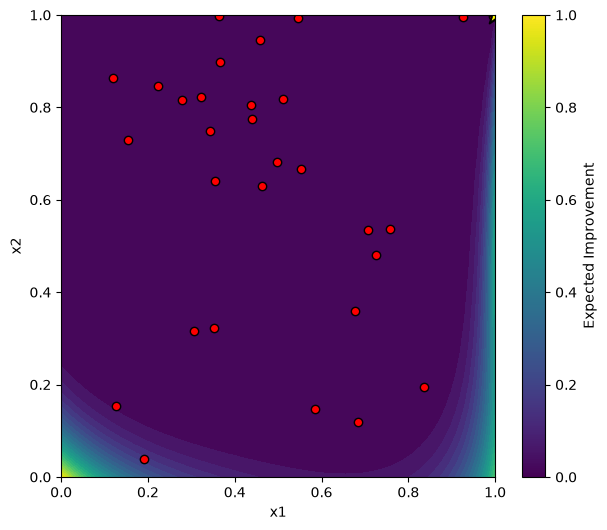

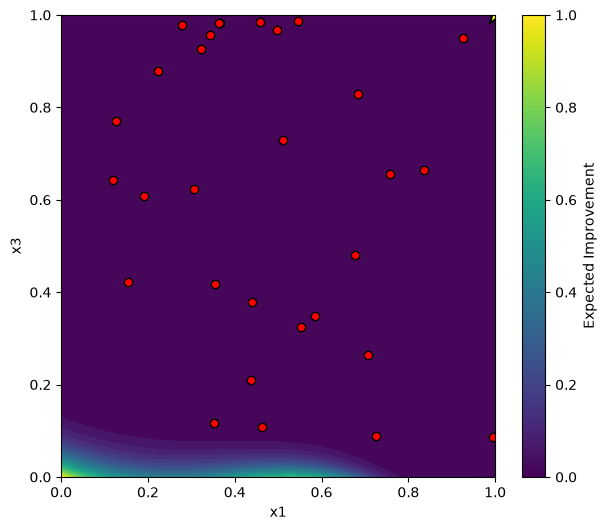

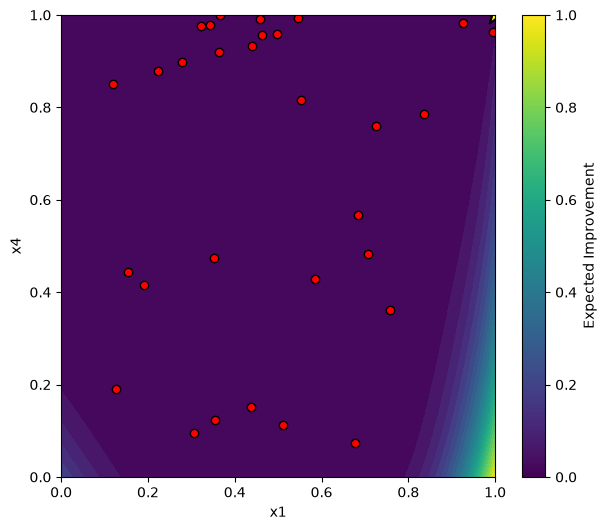

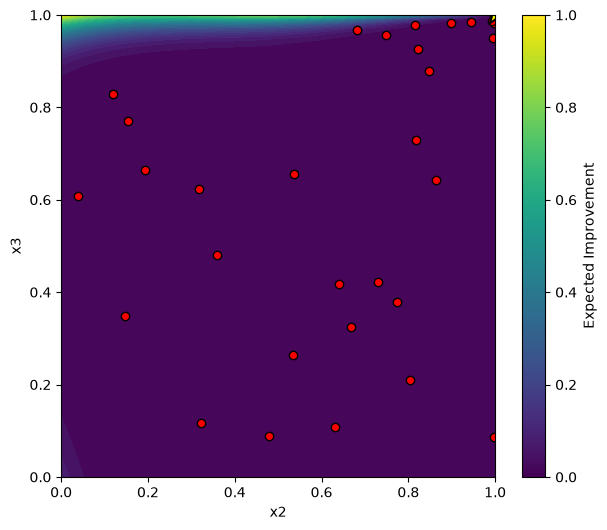

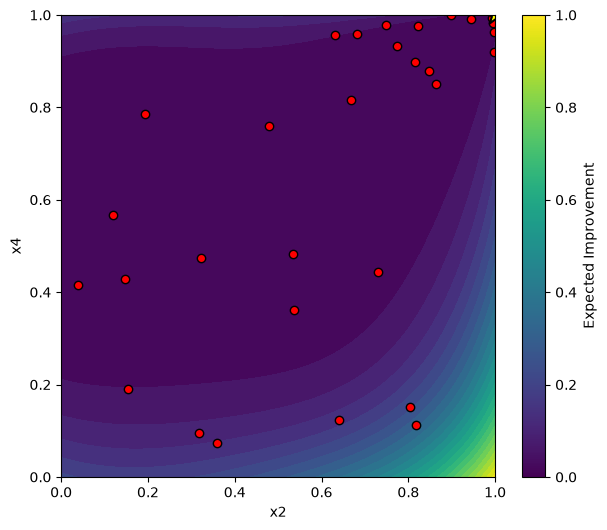

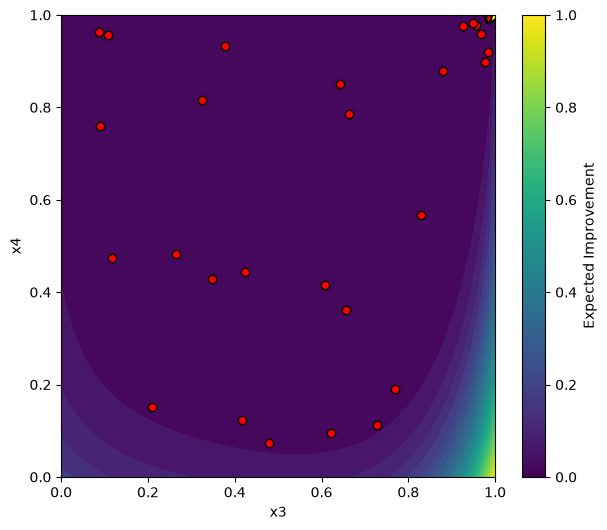

In [ ]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    best_point = X[np.argmax(Y)].copy()

    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    grid = np.tile(best_point, (xx.size, 1))

    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    mu, sigma = gp.predict(grid, return_std=True)

    best_y = np.max(Y)

    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")
    
    plt.show()

plot_EI_slice(gp, X, Y, dim1=0, dim2=1)
plot_EI_slice(gp, X, Y, dim1=0, dim2=2)
plot_EI_slice(gp, X, Y, dim1=0, dim2=3)
plot_EI_slice(gp, X, Y, dim1=1, dim2=2)
plot_EI_slice(gp, X, Y, dim1=1, dim2=3)
plot_EI_slice(gp, X, Y, dim1=2, dim2=3)

In [ ]:
'''
1st point selected: [0.278685-0.815061-0.977174-0.897284]
Output: 1661.4135438315463

2nd point selected: [0.321354-0.821762-0.926927-0.976186]
Output: 1895.4365373086175

3rd point selected: [0.497462-0.681502-0.966971-0.959222]
Output: 1643.85857008234

4th point selected: [0.342225-0.748531-0.956115-0.978741]
Output: 1820.7897949029561

5th point selected: [0.366431-0.897347-0.982957-0.999554]
Output: 3161.147519183887

6th point selected: [0.458619-0.945403-0.985308-0.991250]
Output: 3631.7536257996308

7th point selected: [0.363855-0.997888-0.983432-0.920391]
Output: 3351.6133703569144

8th point selected: [0.546042-0.993762-0.987495-0.993188]
Output: 4421.331411096663

9th point selected: [0.926797-0.995738-0.949160-0.981944]
Output: 6250.946358080354 

10th point selected: [0.994167-0.997906-0.086805-0.963572]
Output: 3872.329495546449 

11th point selected: [0.999999-0.999999-0.999999-0.999999] ---MANUALLY SELECTED---
Output: 8662.405001248297   ---NEW BEST---

12th point selected: [0.984928-0.947312-0.995021-0.014309]
Output: 3542.145163634882 

Final point selected: [0.121859-0.000929-0.024279-0.095393] --- xi reduced to 0, optimiser suggests query near oppposite boundary (0,0,0,0)
Output: 162.53828624532645

In [ ]:
# Updating data with new input-output pairs

# X_query1 = np.array([0.278685,0.815061,0.977174,0.897284], dtype=np.float64)
# Y_query1_output = np.array([1661.4135438315463], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.321354,0.821762,0.926927,0.976186], dtype=np.float64)
# Y_query2_output = np.array([1895.4365373086175], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.497462,0.681502,0.966971,0.959222], dtype=np.float64)
# Y_query3_output = np.array([1643.85857008234], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.342225,0.748531,0.956115,0.978741], dtype=np.float64)
# Y_query4_output = np.array([1820.7897949029561], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.366431,0.897347,0.982957,0.999554], dtype=np.float64)
# Y_query5_output = np.array([3161.147519183887], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.458619,0.945403,0.985308,0.991250], dtype=np.float64)
# Y_query6_output = np.array([3631.7536257996308], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.363855,0.997888,0.983432,0.920391], dtype=np.float64)
# Y_query7_output = np.array([3351.6133703569144], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.546042,0.993762,0.987495,0.993188], dtype=np.float64)
# Y_query8_output = np.array([4421.331411096663], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.926797,0.995738,0.949160,0.981944], dtype=np.float64)
# Y_query9_output = np.array([6250.946358080354], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.994167,0.997906,0.086805,0.963572], dtype=np.float64)
# Y_query10_output = np.array([3872.329495546449], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.999999,0.999999,0.999999,0.999999], dtype=np.float64)
# Y_query11_output = np.array([8662.405001248297], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.984928,0.947312,0.995021,0.014309], dtype=np.float64)
# Y_query12_output = np.array([3542.145163634882], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.121859,0.000929,0.024279,0.095393], dtype=np.float64)
# Y_query13_output = np.array([162.53828624532645], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_5\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_5\initial_outputs.npy", Y_updated)